<a href="https://colab.research.google.com/github/igornvidal/apollo_analytics_academy/blob/main/Desvio_padr%C3%A3o_e_IC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

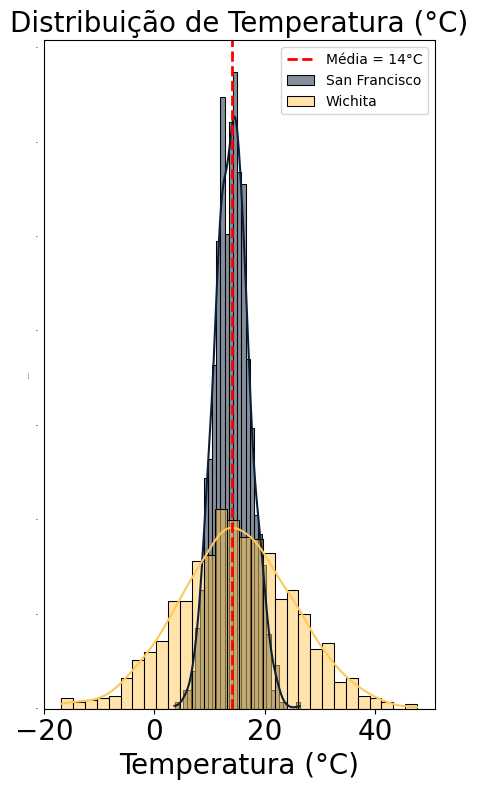

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Fixa a semente para reprodutibilidade
np.random.seed(42)

# População 1: San Francisco (Baixo Desvio Padrão)
# Média = 14.0°C, Sigma ~ 3.2°C
sf_temps = np.random.normal(loc=14.0, scale=3.2, size=1000)

# População 2: Wichita (Alto Desvio Padrão)
# Média = 14.0°C, Sigma ~ 10.5°C
wichita_temps = np.random.normal(loc=14.0, scale=10.5, size=1000)

# Plot do Histograma + KDE
plt.figure(figsize=(4.5,8))

sns.histplot(sf_temps, color="#0b1f3b", label="San Francisco", kde=True, stat="density", alpha=0.5, bins=30)
sns.histplot(wichita_temps, color="#ffc857", label="Wichita", kde=True, stat="density", alpha=0.5, bins=30)

plt.axvline(14.0, color='red', linestyle='--', linewidth=2, label="Média = 14°C")

plt.title("Distribuição de Temperatura (°C)", fontsize=20)
plt.xlabel("Temperatura (°C)", fontsize=20)
plt.ylabel("Densidade", fontsize=0)
plt.legend(fontsize=10,loc = 'best')
plt.tick_params(axis='y', length=0, labelsize=0)
plt.tick_params(axis='x', labelsize=20)
plt.tight_layout()
plt.show()

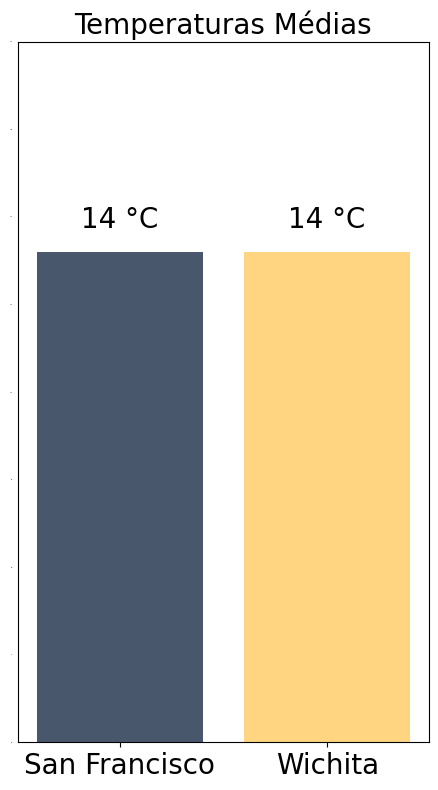

In [ ]:
sf_mean = np.mean(sf_temps)
wichita_mean = np.mean(wichita_temps)

labels = ['San Francisco', 'Wichita']
means = [14, 14]
colors = ['#0b1f3b', '#ffc857']

plt.figure(figsize=(4.5, 8))
plt.bar(labels, means, color=colors, alpha = 0.75)
# plt.ylabel('Temperatura Média (°C)', fontsize=20)
plt.title('Temperaturas Médias', fontsize=20)
plt.ylim(0, 20) # Ajusta o limite Y para melhor visualização

for i, mean in enumerate(means):
    plt.text(i, mean + 0.5, '14 °C', ha='center', va='bottom', fontsize=20)

plt.tick_params(axis='y', length=0, labelsize=0)
plt.tick_params(axis='x', labelsize=20)
plt.tight_layout()
plt.show()

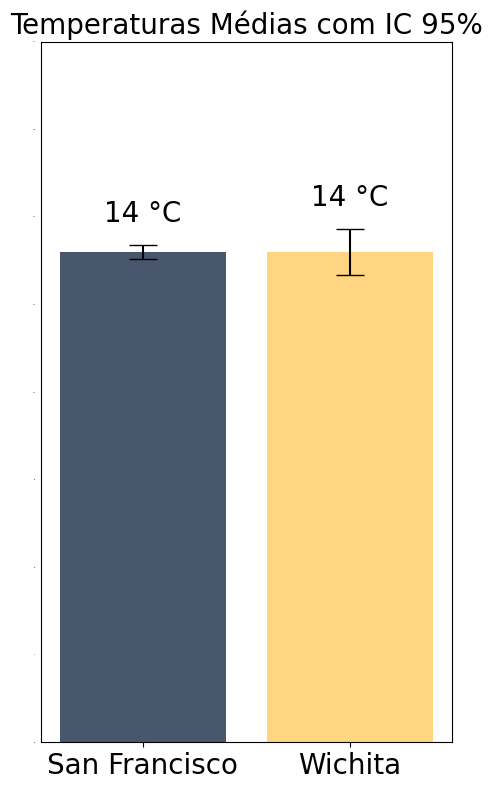

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Calculate means
#sf_mean = np.mean(sf_temps)
sf_mean = 14
#wichita_mean = np.mean(wichita_temps)
wichita_mean = 14

# Number of samples
n_sf = len(sf_temps)
n_wichita = len(wichita_temps)

# Calculate standard errors of the mean (SEM)
sf_sem = stats.sem(sf_temps)
wichita_sem = stats.sem(wichita_temps)

# Calculate 95% Confidence Intervals (CI) using t-distribution
sf_ci_lower, sf_ci_upper = stats.t.interval(confidence=0.95, df=n_sf-1, loc=sf_mean, scale=sf_sem)
wichita_ci_lower, wichita_ci_upper = stats.t.interval(confidence=0.95, df=n_wichita-1, loc=wichita_mean, scale=wichita_sem)

# Error for plotting (distance from mean to each end of CI)
sf_error = sf_mean - sf_ci_lower
wichita_error = wichita_mean - wichita_ci_lower

labels = ['San Francisco', 'Wichita']
means = [sf_mean, wichita_mean]
errors = [sf_error, wichita_error]
colors = ['#0b1f3b', '#ffc857']

plt.figure(figsize=(4.5, 8))
plt.bar(labels, means, yerr=errors, capsize=10, color=colors, alpha = 0.75)

plt.title('Temperaturas Médias com IC 95%', fontsize=20)
# plt.ylabel('Temperatura Média (°C)', fontsize=20)

# Adjust y-limit dynamically based on CI with some padding
min_val = min(sf_ci_lower, wichita_ci_lower)
max_val = max(sf_ci_upper, wichita_ci_upper)
plt.ylim(0,20)

for i, mean_val in enumerate(means):
    # Display the mean value above each error bar
    # The text should be placed above the upper bound of the CI
    plt.text(i, mean_val + errors[i] + 0.5, '14 °C', ha='center', va='bottom', fontsize=20)

plt.tick_params(axis='y', length =0,labelsize=0)
plt.tick_params(axis='x', labelsize=20)
plt.tight_layout()
plt.show()